# Unsupervised — Segmentasi Pelanggan RFM (Recency, Frequency, Monetary)
**Kapan dipakai:** ada data transaksi (pelanggan, tanggal, nilai belanja) dan diminta
mengelompokkan pelanggan untuk strategi pemasaran.

**Idenya:** tiap pelanggan diringkas jadi 3 angka:
- **recency** = berapa hari sejak belanja terakhir (kecil = baru saja belanja).
- **frequency** = berapa kali belanja (jumlah invoice).
- **monetary** = total uang yang dibelanjakan.

Ketiganya di-log (sangat miring), disamakan skalanya, lalu di-cluster. Tiap segmen diberi
nama dari profil rata-ratanya.

**Langkah:**
1. Bersihkan transaksi (buang retur dan harga 0).
2. Hitung RFM per pelanggan.
3. Cluster, lihat profil segmen, simpan segmen tiap pelanggan.

**Data demo:** Online Retail UCI (toko online Inggris 2010–2011).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

## Konfigurasi

In [2]:
DATA_FOLDER = "../../../data_latihan/unsupervised"   # GANTI saat lomba
TRANSACTIONS_CSV = f"{DATA_FOLDER}/online_retail.csv"

CUSTOMER_COL = "CustomerID"
INVOICE_COL = "InvoiceNo"
DATE_COL = "InvoiceDate"
QUANTITY_COL = "Quantity"
PRICE_COL = "UnitPrice"
CANCEL_PREFIX = "C"      # invoice berawalan C = pembatalan
N_CLUSTERS = 4
SEED = 42

## Baca data

In [3]:
transactions = pd.read_csv(TRANSACTIONS_CSV, parse_dates=[DATE_COL])
print(transactions.shape)
print("pelanggan:", transactions[CUSTOMER_COL].nunique())
print("invoice:", transactions[INVOICE_COL].nunique())
transactions.head()

(165225, 8)
pelanggan: 1500
invoice: 8278


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


## Langkah 1 — bersihkan transaksi

setelah bersih: (161733, 9)


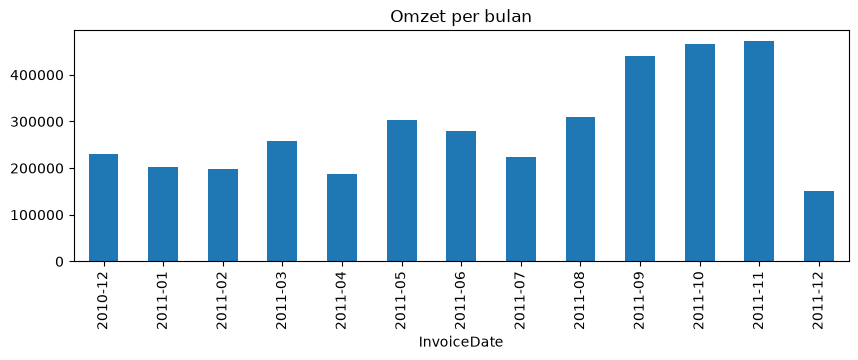

In [4]:
is_valid = (transactions[QUANTITY_COL] > 0) & (transactions[PRICE_COL] > 0)
invoice_text = transactions[INVOICE_COL].astype(str)
is_cancel = invoice_text.str.startswith(CANCEL_PREFIX)
transactions = transactions[is_valid & ~is_cancel].copy()
transactions["total"] = transactions[QUANTITY_COL] * transactions[PRICE_COL]
print("setelah bersih:", transactions.shape)

month = transactions[DATE_COL].dt.to_period("M")
monthly_sales = transactions.groupby(month)["total"].sum()
monthly_sales.plot.bar(figsize=(10, 3))
plt.title("Omzet per bulan")
plt.show()

## Langkah 2 — RFM per pelanggan
Tanggal acuan = sehari setelah transaksi terakhir di data.

In [5]:
reference_date = transactions[DATE_COL].max() + pd.DateOffset(days=1)
per_customer = transactions.groupby(CUSTOMER_COL)
last_purchase = per_customer[DATE_COL].max()

rfm = pd.DataFrame()
rfm["recency"] = (reference_date - last_purchase).dt.days
rfm["frequency"] = per_customer[INVOICE_COL].nunique()
rfm["monetary"] = per_customer["total"].sum()
print(rfm.describe().round(1))

scaler = StandardScaler()
X = scaler.fit_transform(np.log1p(rfm))      # log(1 + x) meredam nilai yang sangat besar

       recency  frequency  monetary
count   1489.0     1489.0    1489.0
mean      91.6        4.6    2499.1
std      100.0        9.4   12907.0
min        1.0        1.0       6.2
25%       17.0        1.0     311.3
50%       50.0        2.0     660.0
75%      139.0        5.0    1740.6
max      374.0      201.0  280206.0


## Pilih jumlah segmen
Silhouette tinggi = segmen rapat dan saling terpisah. Tulis pilihan di `N_CLUSTERS`.
Jumlah 3–5 biasanya paling mudah dijelaskan saat presentasi.

In [6]:
for count in range(2, 9):
    kmeans = KMeans(n_clusters=count, n_init=10, random_state=SEED)
    trial_labels = kmeans.fit_predict(X)
    print(count, "segmen | silhouette:", round(silhouette_score(X, trial_labels), 3))

2 segmen | silhouette: 0.425
3 segmen | silhouette: 0.337


4 segmen | silhouette: 0.345
5 segmen | silhouette: 0.316


6 segmen | silhouette: 0.312
7 segmen | silhouette: 0.305


8 segmen | silhouette: 0.302


## Langkah 3 — model
Pilih SATU model: hapus `#` di depan baris yang ingin dipakai, beri `#` pada baris lain.

In [7]:
model = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED)
# model = GaussianMixture(n_components=N_CLUSTERS, random_state=SEED)
# model = AgglomerativeClustering(n_clusters=N_CLUSTERS, linkage="ward")

labels = model.fit_predict(X)
rfm["segment"] = labels
print("silhouette:", round(silhouette_score(X, labels), 3))

silhouette: 0.345


## Profil segmen (bahan presentasi)
Contoh penamaan: recency kecil + frequency/monetary besar = "Pelanggan setia",
recency besar + frequency kecil = "Hampir hilang".

         recency  frequency  monetary  n_customers  sales_share_%
segment                                                          
0           16.0        2.0     483.3          299            4.7
1            7.0       11.0    4139.5          217           68.5
2          172.5        1.0     302.2          568            5.5
3           51.0        4.0    1497.0          405           21.3


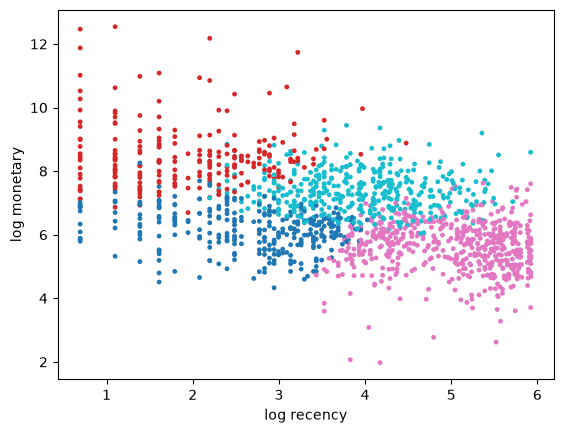

In [8]:
profile = rfm.groupby("segment").median()
profile["n_customers"] = rfm.groupby("segment").size()
segment_money = rfm.groupby("segment")["monetary"].sum()
profile["sales_share_%"] = segment_money / rfm["monetary"].sum() * 100
print(profile.round(1))

plt.scatter(np.log1p(rfm["recency"]), np.log1p(rfm["monetary"]), c=labels, cmap="tab10", s=6)
plt.xlabel("log recency")
plt.ylabel("log monetary")
plt.show()

## Simpan segmen tiap pelanggan

In [9]:
submission = pd.DataFrame()
submission["CustomerID"] = rfm.index
submission["recency"] = rfm["recency"].to_numpy()
submission["frequency"] = rfm["frequency"].to_numpy()
submission["monetary"] = rfm["monetary"].to_numpy()
submission["segment"] = labels
submission.to_csv("submission.csv", index=False)
submission.head()

,CustomerID,recency,frequency,monetary,segment
0,12347,2,7,4310.00,1
1,12350,310,1,334.40,2
2,12358,2,2,1168.06,0
3,12370,51,4,3545.69,3
4,12374,25,1,742.93,0
